# Лабораторная работа №1
## Настройка среды разработки и управление виртуальными окружениями

**Окружение:** `lab1_terminal` (Anaconda, Python 3.11)

Содержание блокнота:
1. Аудит окружения и аппаратных ресурсов
2. Программная проверка версий пакетов `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`
3. Экспериментальная проверка на двух наборах данных (загрузка через `pandas` + построение графиков)

## 1. Идентификация активного окружения

In [1]:
import sys, os, platform

print("Интерпретатор Python :", sys.executable)
print("Версия Python        :", sys.version.split()[0])
print("Активное окружение   :", os.environ.get("CONDA_DEFAULT_ENV", "не определено"))
print("Префикс окружения    :", sys.prefix)
print("Платформа            :", platform.platform())
print("Архитектура          :", platform.machine())

Интерпретатор Python : /opt/anaconda3/envs/lab1_terminal/bin/python
Версия Python        : 3.11.16
Активное окружение   : lab1_terminal
Префикс окружения    : /opt/anaconda3/envs/lab1_terminal
Платформа            : macOS-15.0-arm64-arm-64bit
Архитектура          : arm64


Вывод подтверждает, что блокнот исполняется в **изолированном** окружении
`lab1_terminal`, а не в `base`: путь к интерпретатору указывает
на `/opt/anaconda3/envs/lab1_terminal/bin/python`.

## 2. Первичный аудит аппаратных ресурсов

In [2]:
import multiprocessing, subprocess, shutil

print("Логических ядер CPU  :", multiprocessing.cpu_count())

def sysctl(key):
    try:
        return subprocess.check_output(["sysctl", "-n", key], text=True).strip()
    except Exception:
        return "н/д"

print("Модель               :", sysctl("hw.model"))
print("Процессор            :", sysctl("machdep.cpu.brand_string"))
print("Физических ядер      :", sysctl("hw.physicalcpu"))
mem = sysctl("hw.memsize")
print("Оперативная память   :", f"{int(mem)/1024**3:.0f} GB" if mem.isdigit() else "н/д")

total, used, free = shutil.disk_usage("/")
print("Диск (/)             :", f"{total/1024**3:.0f} GB всего, {free/1024**3:.0f} GB свободно")

print("\nПроверка наличия CUDA-ускорителя:")
if shutil.which("nvidia-smi"):
    print(subprocess.check_output(["nvidia-smi"], text=True))
else:
    print("  nvidia-smi отсутствует -> дискретного NVIDIA GPU нет.")
    print("  Локальная машина: Apple Silicon, ускорение доступно через Metal (MPS).")

Логических ядер CPU  : 8
Модель               : Mac15,13
Процессор            : Apple M3
Физических ядер      : 8
Оперативная память   : 16 GB
Диск (/)             : 460 GB всего, 157 GB свободно

Проверка наличия CUDA-ускорителя:
  nvidia-smi отсутствует -> дискретного NVIDIA GPU нет.
  Локальная машина: Apple Silicon, ускорение доступно через Metal (MPS).


## 3. Программное определение версий установленных пакетов

In [3]:
import importlib

packages = {
    "numpy":        "numpy",
    "pandas":       "pandas",
    "matplotlib":   "matplotlib",
    "seaborn":      "seaborn",
    "scikit-learn": "sklearn",
}

print(f"{'Пакет':<15}{'Импортируемое имя':<20}{'Статус':<12}Версия")
print("-" * 62)
versions = {}
for dist, module in packages.items():
    try:
        m = importlib.import_module(module)
        v = getattr(m, "__version__", "н/д")
        versions[dist] = v
        print(f"{dist:<15}{module:<20}{'установлен':<12}{v}")
    except ImportError:
        versions[dist] = None
        print(f"{dist:<15}{module:<20}{'ОТСУТСТВУЕТ':<12}-")

Пакет          Импортируемое имя   Статус      Версия
--------------------------------------------------------------


numpy          numpy               установлен  2.4.6


pandas         pandas              установлен  3.0.5


matplotlib     matplotlib          установлен  3.11.0


Matplotlib is building the font cache; this may take a moment.


seaborn        seaborn             установлен  0.13.2


scikit-learn   sklearn             установлен  1.9.0


Альтернативный способ — через `importlib.metadata`, работает без импорта самих пакетов:

In [4]:
from importlib.metadata import version, PackageNotFoundError

for dist in ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn"]:
    try:
        print(f"{dist:<15}{version(dist)}")
    except PackageNotFoundError:
        print(f"{dist:<15}не установлен")

numpy          2.4.6
pandas         3.0.5
matplotlib     3.11.0
seaborn        0.13.2
scikit-learn   1.9.0


Тот же результат можно получить магической командой Jupyter, обращающейся к менеджеру пакетов:

In [5]:
!conda list | grep -E "^(numpy|pandas|matplotlib|seaborn|scikit-learn) " 

matplotlib                   3.11.0           py311hca03da5_0
numpy                        2.4.6            py311heca761d_0
pandas                       3.0.5            py311h3f644e9_0
scikit-learn                 1.9.0            py311h3f644e9_0
seaborn                      0.13.2           py311hca03da5_3


## 4. Экспериментальная проверка на наборах данных

Используются два различных набора данных, поставляемых с `scikit-learn`.
Чтобы продемонстрировать именно загрузку средствами `pandas`, наборы
предварительно выгружаются в файлы CSV, а затем читаются через `pd.read_csv()`.

In [6]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris, load_wine
from pathlib import Path

DATA = Path("data"); DATA.mkdir(exist_ok=True)
FIG  = Path("figures"); FIG.mkdir(exist_ok=True)

# Датасет 1 — Iris (классификация видов ирисов по морфологии цветка)
iris = load_iris(as_frame=True)
df_iris = iris.frame.copy()
df_iris["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)
df_iris.to_csv(DATA / "iris.csv", index=False)

# Датасет 2 — Wine (химический анализ вин трёх сортов)
wine = load_wine(as_frame=True)
df_wine = wine.frame.copy()
df_wine["wine_class"] = pd.Categorical.from_codes(wine.target, wine.target_names)
df_wine.to_csv(DATA / "wine.csv", index=False)

sns.set_theme(style="whitegrid")
print("CSV-файлы сохранены:", [p.name for p in sorted(DATA.glob('*.csv'))])

CSV-файлы сохранены: ['iris.csv', 'wine.csv']


### 4.1. Набор данных №1 — Iris

In [7]:
df1 = pd.read_csv("data/iris.csv")

print("Размерность (строк, столбцов):", df1.shape)
print("\nТипы данных:")
print(df1.dtypes)
print("\nПропущенные значения:", int(df1.isna().sum().sum()))
print("\nРаспределение по классам:")
print(df1["species"].value_counts())
df1.head()

Размерность (строк, столбцов): (150, 6)

Типы данных:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species                  str
dtype: object

Пропущенные значения: 0

Распределение по классам:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [8]:
df1.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


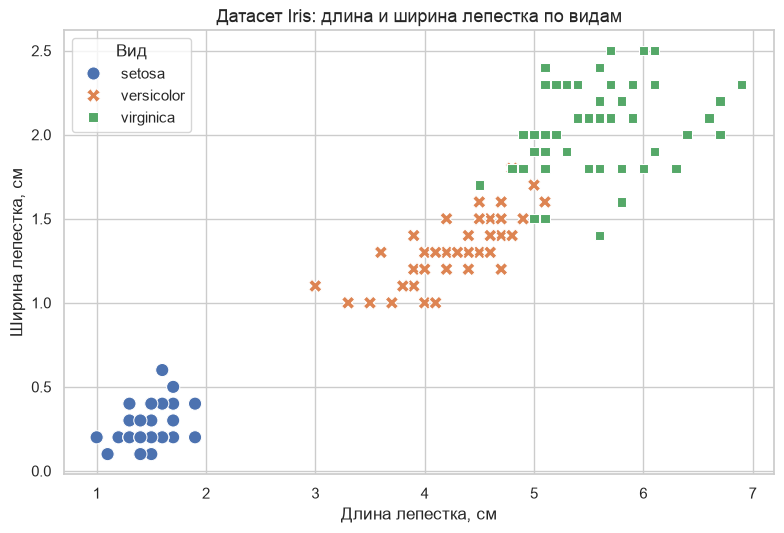

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(
    data=df1, x="petal length (cm)", y="petal width (cm)",
    hue="species", style="species", s=90, ax=ax,
)
ax.set_title("Датасет Iris: длина и ширина лепестка по видам", fontsize=13)
ax.set_xlabel("Длина лепестка, см")
ax.set_ylabel("Ширина лепестка, см")
ax.legend(title="Вид")
fig.tight_layout()
fig.savefig("figures/iris_scatter.png", dpi=150)
plt.show()

На графике видно, что вид *setosa* линейно отделим от двух остальных
по размерам лепестка, а *versicolor* и *virginica* частично перекрываются —
классический результат для этого набора данных.

### 4.2. Набор данных №2 — Wine

In [10]:
df2 = pd.read_csv("data/wine.csv")

print("Размерность (строк, столбцов):", df2.shape)
print("\nПризнаки:", ", ".join(df2.columns[:6]), "...")
print("\nПропущенные значения:", int(df2.isna().sum().sum()))
print("\nРаспределение по классам:")
print(df2["wine_class"].value_counts())
df2.head()

Размерность (строк, столбцов): (178, 15)

Признаки: alcohol, malic_acid, ash, alcalinity_of_ash, magnesium, total_phenols ...

Пропущенные значения: 0

Распределение по классам:
wine_class
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,wine_class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [11]:
df2[["alcohol", "malic_acid", "color_intensity", "proline"]].describe().round(2)

,alcohol,malic_acid,color_intensity,proline
count,178.00,178.00,178.00,178.00
mean,13.00,2.34,5.06,746.89
std,0.81,1.12,2.32,314.91
min,11.03,0.74,1.28,278.00
25%,12.36,1.60,3.22,500.50
50%,13.05,1.87,4.69,673.50
75%,13.68,3.08,6.20,985.00
max,14.83,5.80,13.00,1680.00


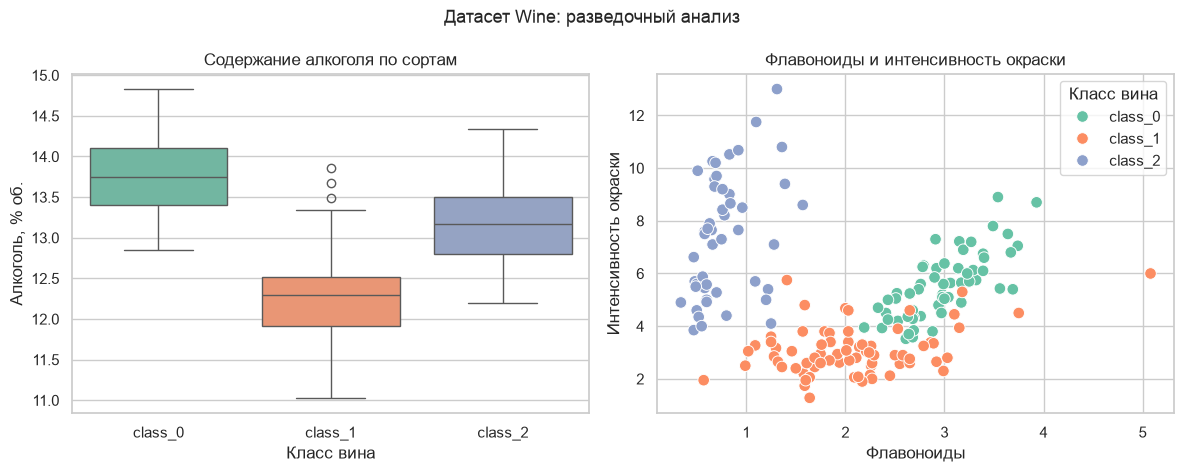

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

sns.boxplot(data=df2, x="wine_class", y="alcohol", hue="wine_class",
            palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Содержание алкоголя по сортам")
axes[0].set_xlabel("Класс вина"); axes[0].set_ylabel("Алкоголь, % об.")

sns.scatterplot(data=df2, x="flavanoids", y="color_intensity",
                hue="wine_class", palette="Set2", s=70, ax=axes[1])
axes[1].set_title("Флавоноиды и интенсивность окраски")
axes[1].set_xlabel("Флавоноиды"); axes[1].set_ylabel("Интенсивность окраски")
axes[1].legend(title="Класс вина")

fig.suptitle("Датасет Wine: разведочный анализ", fontsize=13)
fig.tight_layout()
fig.savefig("figures/wine_plots.png", dpi=150)
plt.show()

Классы вин заметно различаются по содержанию алкоголя и по паре
«флавоноиды — интенсивность окраски», что подтверждает корректную работу
связки `pandas` + `matplotlib` + `seaborn` в созданном окружении.

### 4.3. Контрольная проверка `scikit-learn`

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

for name, df, target in [("Iris", df1, "species"), ("Wine", df2, "wine_class")]:
    X = df.drop(columns=[target, "target"], errors="ignore")
    y = df[target]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, model.predict(X_te))
    print(f"{name:<6} логистическая регрессия, accuracy на тесте: {acc:.3f}")

Iris   логистическая регрессия, accuracy на тесте: 0.911
Wine   логистическая регрессия, accuracy на тесте: 0.981


## 5. Вывод

В созданном изолированном окружении `lab1_terminal` корректно установлены и
работают все требуемые библиотеки: выполнены импорт, загрузка данных через
`pandas`, построение графиков средствами `matplotlib` и `seaborn`, а также
обучение модели `scikit-learn`. Среда разработки готова к дальнейшим работам.